In [1]:
import pandas as pd
import string
import seaborn as sns
import matplotlib.pyplot as plt

In [66]:
google = pd.read_csv('googleplaystore.csv')
ios = pd.read_csv('AppleStore.csv')

In [3]:
google.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [71]:
ios.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7197 entries, 0 to 7196
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                7197 non-null   int64  
 1   track_name        7197 non-null   object 
 2   size_bytes        7197 non-null   int64  
 3   currency          7197 non-null   object 
 4   price             7197 non-null   float64
 5   rating_count_tot  7197 non-null   int64  
 6   rating_count_ver  7197 non-null   int64  
 7   user_rating       7197 non-null   float64
 8   user_rating_ver   7197 non-null   float64
 9   ver               7197 non-null   object 
 10  cont_rating       7197 non-null   object 
 11  prime_genre       7197 non-null   object 
 12  sup_devices.num   7197 non-null   int64  
 13  ipadSc_urls.num   7197 non-null   int64  
 14  lang.num          7197 non-null   int64  
 15  vpp_lic           7197 non-null   int64  
dtypes: float64(3), int64(8), object(5)
memory 

In [72]:
ios.head()

,id,track_name,size_bytes,currency,price,rating_count_tot,rating_count_ver,user_rating,user_rating_ver,ver,cont_rating,prime_genre,sup_devices.num,ipadSc_urls.num,lang.num,vpp_lic
0,284882215,Facebook,389879808,USD,0.0,2974676,212,3.5,3.5,95.0,4+,Social Networking,37,1,29,1
1,389801252,Instagram,113954816,USD,0.0,2161558,1289,4.5,4.0,10.23,12+,Photo & Video,37,0,29,1
2,529479190,Clash of Clans,116476928,USD,0.0,2130805,579,4.5,4.5,9.24.12,9+,Games,38,5,18,1
3,420009108,Temple Run,65921024,USD,0.0,1724546,3842,4.5,4.0,1.6.2,9+,Games,40,5,1,1
4,284035177,Pandora - Music & Radio,130242560,USD,0.0,1126879,3594,4.0,4.5,8.4.1,12+,Music,37,4,1,1


In [4]:
google.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [70]:
google.shape

(10841, 13)

In [71]:
google.iloc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              1.9
Rating                                               19.0
Reviews                                              3.0M
Size                                               1,000+
Installs                                             Free
Type                                                    0
Price                                            Everyone
Content Rating                                        NaN
Genres                                  February 11, 2018
Last Updated                                       1.0.19
Current Ver                                    4.0 and up
Android Ver                                           NaN
Name: 10472, dtype: object

In [72]:
google = google.drop(index = 10472)

In [73]:
google['App'].duplicated().sum()

1181

In [74]:
duplicate_data = google[google['App'].duplicated()]

In [75]:
google.drop_duplicates(subset = ['App'],inplace = True)

In [76]:
grouped = duplicate_data.groupby('App', as_index = False)['Reviews'].max()

In [77]:
google = google.merge(grouped, on = 'App', how = 'left', suffixes = ("",'_max'))

In [78]:
google['Reviews'] = google['Reviews_max'].combine_first(google['Reviews'])

In [79]:
google.drop(columns = ['Reviews_max'],inplace = True)

In [80]:
google.shape

(9659, 13)

In [13]:
google = pd.read_pickle('google1.pkl')

In [14]:
def is_english(string):
    non_ascii = 0
    
    for character in string:
        if ord(character) > 127:
            non_ascii += 1
    
    if non_ascii > 3:
        return False
    else:
        return True

In [15]:
google = google[google['App'].apply(is_english)]

In [16]:
google

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,974,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9654,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
9655,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
9656,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
9657,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device


In [17]:
google.isna().sum()

App                  0
Category             0
Rating            1448
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [19]:
google['Rating'] = google['Rating'].fillna(google['Rating'].median())

In [23]:
google['Type'] = google['Type'].fillna('Free') 

In [25]:
google['Current Ver'].describe()

count                   9606
unique                  2813
top       Varies with device
freq                    1053
Name: Current Ver, dtype: object

In [26]:
google['Current Ver'] = google['Current Ver'].fillna('Varies with device')

In [28]:
google['Android Ver'].describe()

count           9612
unique            33
top       4.1 and up
freq            2194
Name: Android Ver, dtype: object

In [29]:
google['Android Ver'] = google['Android Ver'].fillna('4.1 and up')

In [30]:
google.isna().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

In [35]:
google['Last Updated'] = pd.to_datetime(google['Last Updated'])

In [37]:
google.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9614 entries, 0 to 9658
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9614 non-null   object        
 1   Category        9614 non-null   object        
 2   Rating          9614 non-null   float64       
 3   Reviews         9614 non-null   object        
 4   Size            9614 non-null   object        
 5   Installs        9614 non-null   object        
 6   Type            9614 non-null   object        
 7   Price           9614 non-null   object        
 8   Content Rating  9614 non-null   object        
 9   Genres          9614 non-null   object        
 10  Last Updated    9614 non-null   datetime64[ns]
 11  Current Ver     9614 non-null   object        
 12  Android Ver     9614 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(11)
memory usage: 1.0+ MB


In [38]:
google.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,974,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up


In [67]:
ios.isna().sum()

id                  0
track_name          0
size_bytes          0
currency            0
price               0
rating_count_tot    0
rating_count_ver    0
user_rating         0
user_rating_ver     0
ver                 0
cont_rating         0
prime_genre         0
sup_devices.num     0
ipadSc_urls.num     0
lang.num            0
vpp_lic             0
dtype: int64

In [75]:
ios.duplicated().sum()

0

In [77]:
ios = ios[ios['track_name'].apply(is_english)]

In [78]:
google.to_pickle('Google_cleaned.pkl')
ios.to_pickle('ios_cleaned.pkl')

In [79]:
free_g = google[google['Type'] == 'Free']

In [90]:
free_ios = ios[ios['price'] == 0.00]

In [80]:
free_g.shape

(8862, 13)

In [91]:
free_ios.shape

(3222, 16)

In [92]:
free_g.to_pickle('Free_apps_google_playstore.pkl')
free_ios.to_pickle('Free_apps_appstore.pkl')

In [2]:
free_ios = pd.read_pickle('Free_apps_appstore.pkl')
free_and = pd.read_pickle('Free_apps_google_playstore.pkl')

<h1>Analysis</h1>

In [93]:
free_g.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,974,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up


In [94]:
free_ios.head(2)

,id,track_name,size_bytes,currency,price,rating_count_tot,rating_count_ver,user_rating,user_rating_ver,ver,cont_rating,prime_genre,sup_devices.num,ipadSc_urls.num,lang.num,vpp_lic
0,284882215,Facebook,389879808,USD,0.0,2974676,212,3.5,3.5,95.0,4+,Social Networking,37,1,29,1
1,389801252,Instagram,113954816,USD,0.0,2161558,1289,4.5,4.0,10.23,12+,Photo & Video,37,0,29,1


In [100]:
freq_category_google = free_g['Category'].value_counts(normalize = True)*100

In [167]:
freq_category_google = freq_category_google.nlargest(10, 'proportion')

In [168]:
freq_category_google

,Category,proportion
0,FAMILY,18.449560
1,GAME,9.873618
2,TOOLS,8.440533
3,BUSINESS,4.592643
4,LIFESTYLE,3.904311
5,PRODUCTIVITY,3.893026
6,FINANCE,3.701196
7,MEDICAL,3.520650
8,SPORTS,3.396524
9,PERSONALIZATION,3.317536


In [104]:
freq_genre_ios = free_ios['prime_genre'].value_counts(normalize = True)*100

In [176]:
freq_genre_ios = freq_genre_ios.nlargest(10, 'proportion')

In [177]:
freq_genre_ios

,prime_genre,proportion
0,Games,58.162632
1,Entertainment,7.883302
2,Photo & Video,4.965860
3,Education,3.662322
4,Social Networking,3.289882
5,Shopping,2.607076
6,Utilities,2.513966
7,Sports,2.141527
8,Music,2.048417
9,Health & Fitness,2.017381


Text(0.5, 1.0, 'Most Common Apps by Category App Store')

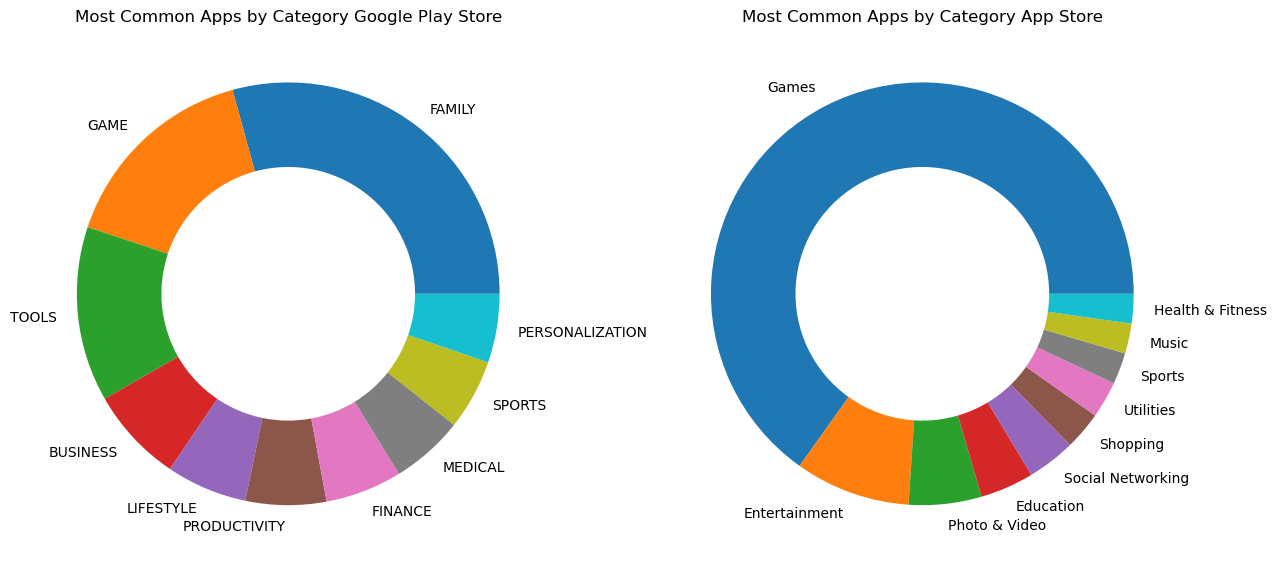

In [186]:
ig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15,15))
ax1.pie(freq_category_google['proportion'], labels = freq_category_google['Category'],
        wedgeprops = {'width':0.4},labeldistance = 1.1)
ax1.set_title('Most Common Apps by Category Google Play Store')

ax2.pie(freq_genre_ios['proportion'], labels = freq_genre_ios['prime_genre'],
        wedgeprops = {'width':0.4},labeldistance = 1.1)
ax2.set_title('Most Common Apps by Category App Store')

<b> Most Popular apps by Genre on the App Store

In [4]:
free_ios.head()

,id,track_name,size_bytes,currency,price,rating_count_tot,rating_count_ver,user_rating,user_rating_ver,ver,cont_rating,prime_genre,sup_devices.num,ipadSc_urls.num,lang.num,vpp_lic
0,284882215,Facebook,389879808,USD,0.0,2974676,212,3.5,3.5,95.0,4+,Social Networking,37,1,29,1
1,389801252,Instagram,113954816,USD,0.0,2161558,1289,4.5,4.0,10.23,12+,Photo & Video,37,0,29,1
2,529479190,Clash of Clans,116476928,USD,0.0,2130805,579,4.5,4.5,9.24.12,9+,Games,38,5,18,1
3,420009108,Temple Run,65921024,USD,0.0,1724546,3842,4.5,4.0,1.6.2,9+,Games,40,5,1,1
4,284035177,Pandora - Music & Radio,130242560,USD,0.0,1126879,3594,4.0,4.5,8.4.1,12+,Music,37,4,1,1


In [3]:
popular_ios = free_ios.groupby('prime_genre')['rating_count_tot'].mean().reset_index()

In [4]:
popular_ios.sort_values(by = 'rating_count_tot',ascending = False, inplace = True)
popular_ios

,prime_genre,rating_count_tot
12,Navigation,86090.333333
16,Reference,74942.111111
18,Social Networking,71548.349057
11,Music,57326.530303
22,Weather,52279.892857
0,Book,39758.500000
6,Food & Drink,33333.923077
5,Finance,31467.944444
14,Photo & Video,28441.543750
20,Travel,28243.800000


[Text(0.5, 1.0, 'Most popular Genre in Apple Sotre'),
 Text(0, 0.5, 'Ratting'),
 Text(0.5, 0, 'Genre')]

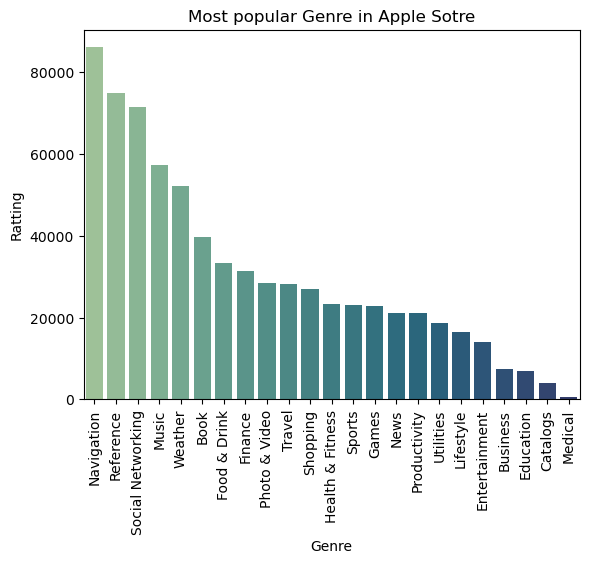

In [9]:
viz_2 = sns.barplot(popular_ios, x = 'prime_genre', y = 'rating_count_tot',palette = 'crest')
viz_2.set_xticklabels(viz_2.get_xticklabels(), rotation = 90)
viz_2.set(title = 'Most popular Genre in Apple Sotre', ylabel = 'Ratting', xlabel = 'Genre')

In [21]:
navigation_ios = free_ios.loc[free_ios['prime_genre'] == 'Navigation', ['track_name','rating_count_tot']].nlargest(10, columns = 'rating_count_tot')
navigation_ios

,track_name,rating_count_tot
49,"Waze - GPS Navigation, Maps & Real-time Traffic",345046
130,Google Maps - Navigation & Transit,154911
881,Geocaching®,12811
1633,CoPilot GPS – Car Navigation & Offline Maps,3582
3987,ImmobilienScout24: Real Estate Search in Germany,187
6033,Railway Route Search,5


In [22]:
reference_ios = free_ios.loc[free_ios['prime_genre'] == 'Reference', ['track_name','rating_count_tot']].nlargest(10, columns = 'rating_count_tot')
reference_ios

,track_name,rating_count_tot
6,Bible,985920
90,Dictionary.com Dictionary & Thesaurus,200047
335,Dictionary.com Dictionary & Thesaurus for iPad,54175
551,Google Translate,26786
715,"Muslim Pro: Ramadan 2017 Prayer Times, Azan, Q...",18418
738,New Furniture Mods - Pocket Wiki & Game Tools ...,17588
757,Merriam-Webster Dictionary,16849
913,Night Sky,12122
1106,City Maps for Minecraft PE - The Best Maps for...,8535
1451,LUCKY BLOCK MOD ™ for Minecraft PC Edition - T...,4693


In [23]:
social_media = free_ios.loc[free_ios['prime_genre'] == 'Social Networking', ['track_name','rating_count_tot']].nlargest(10, columns = 'rating_count_tot')
social_media

,track_name,rating_count_tot
0,Facebook,2974676
5,Pinterest,1061624
43,Skype for iPhone,373519
48,Messenger,351466
51,Tumblr,334293
63,WhatsApp Messenger,287589
72,Kik,260965
111,"ooVoo – Free Video Call, Text and Voice",177501
117,TextNow - Unlimited Text + Calls,164963
120,Viber Messenger – Text & Call,164249


In [24]:
music_ios = free_ios.loc[free_ios['prime_genre'] == 'Music', ['track_name','rating_count_tot']].nlargest(10, columns = 'rating_count_tot')
music_ios

,track_name,rating_count_tot
4,Pandora - Music & Radio,1126879
8,Spotify Music,878563
35,"Shazam - Discover music, artists, videos & lyrics",402925
60,iHeartRadio – Free Music & Radio Stations,293228
151,SoundCloud - Music & Audio,135744
155,Magic Piano by Smule,131695
176,Smule Sing!,119316
191,TuneIn Radio - MLB NBA Audiobooks Podcasts Music,110420
205,Amazon Music,106235
246,SoundHound Song Search & Music Player,82602


In [25]:
wheather_ios = free_ios.loc[free_ios['prime_genre'] == 'Weather', ['track_name','rating_count_tot']].nlargest(10, columns = 'rating_count_tot')
wheather_ios

,track_name,rating_count_tot
22,"The Weather Channel: Forecast, Radar & Alerts",495626
89,The Weather Channel App for iPad – best local ...,208648
95,"WeatherBug - Local Weather, Radar, Maps, Alerts",188583
133,MyRadar NOAA Weather Radar Forecast,150158
138,AccuWeather - Weather for Life,144214
189,Yahoo Weather,112603
355,Weather Underground: Custom Forecast & Local R...,49192
374,NOAA Weather Radar - Weather Forecast & HD Radar,45696
443,Weather Live Free - Weather Forecast & Alerts,35702
619,Storm Radar,22792


[Text(0.5, 0, 'Ratings'), Text(0, 0.5, 'App Name')]

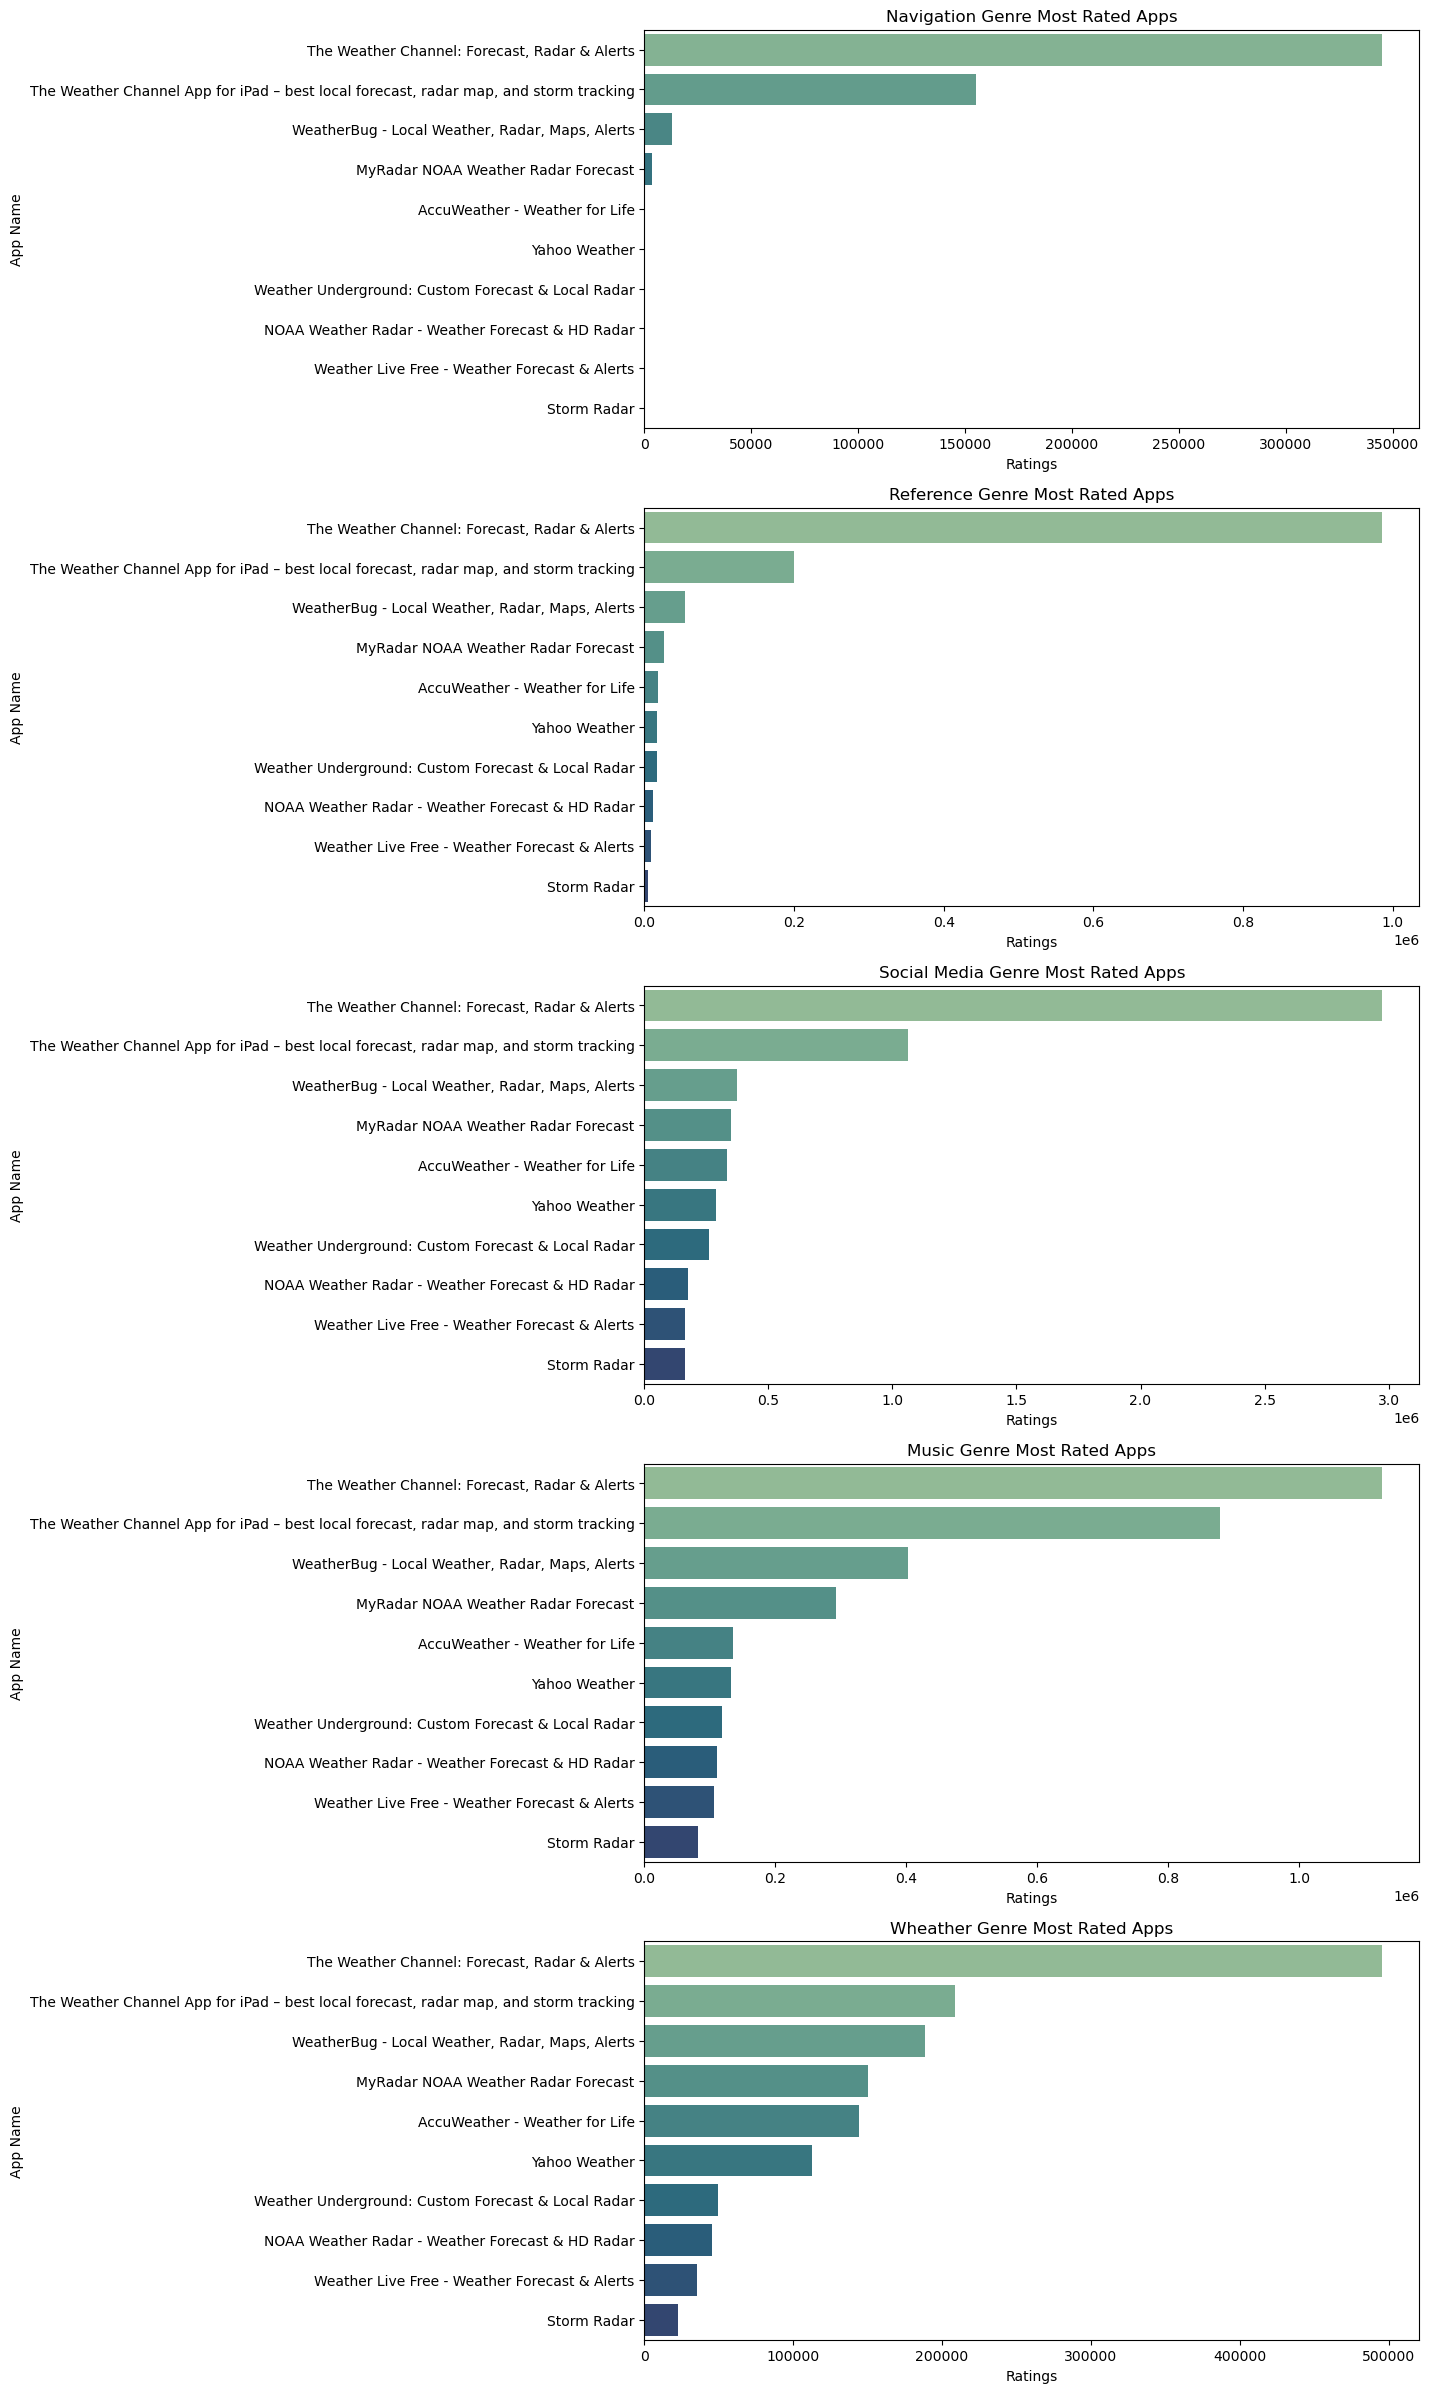

In [51]:
fig, axes = plt.subplots(5, 1, figsize=(10,30), sharey=True)

viz_3 = sns.barplot(navigation_ios, x = 'rating_count_tot', y = 'track_name', palette = 'crest', orient = 'h', ax =axes[0])
viz_3.set(title = 'Navigation Genre Most Rated Apps')
viz_3.set(xlabel= ('Ratings'), ylabel = ('App Name'))

viz_4 = sns.barplot(reference_ios, x = 'rating_count_tot', y = 'track_name', palette = 'crest', orient = 'h', ax =axes[1])
viz_4.set(title = 'Reference Genre Most Rated Apps')
viz_4.set(xlabel= ('Ratings'), ylabel = ('App Name'))

viz_5 = sns.barplot(social_media, x = 'rating_count_tot', y = 'track_name', palette = 'crest', orient = 'h', ax =axes[2])
viz_5.set(title = 'Social Media Genre Most Rated Apps')
viz_5.set(xlabel= ('Ratings'), ylabel = ('App Name'))

viz_6 = sns.barplot(music_ios, x = 'rating_count_tot', y = 'track_name', palette = 'crest', orient = 'h', ax =axes[3])
viz_6.set(title = 'Music Genre Most Rated Apps')
viz_6.set(xlabel= ('Ratings'), ylabel = ('App Name'))

viz_7 = sns.barplot(wheather_ios, x = 'rating_count_tot', y = 'track_name', palette = 'crest', orient = 'h', ax =axes[4])
viz_7.set(title = 'Wheather Genre Most Rated Apps')
viz_7.set(xlabel= ('Ratings'), ylabel = ('App Name'))


<b> Most popular Apps by Category on Google Playstore

In [12]:
free_and.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,974,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up


In [16]:
 free_and['Installs'].info()

<class 'pandas.core.series.Series'>
Index: 8862 entries, 0 to 9658
Series name: Installs
Non-Null Count  Dtype 
--------------  ----- 
8862 non-null   object
dtypes: object(1)
memory usage: 138.5+ KB


In [4]:
free_and['Installs'] = free_and['Installs'].str.replace(',','').str.replace('+','').astype(float)

In [5]:
free_and['Installs'].info()

<class 'pandas.core.series.Series'>
Index: 8862 entries, 0 to 9658
Series name: Installs
Non-Null Count  Dtype  
--------------  -----  
8862 non-null   float64
dtypes: float64(1)
memory usage: 138.5 KB


In [20]:
popular_and = free_and.groupby(free_and.Category)['Installs'].mean().reset_index()
popular_and

,Category,Installs
0,ART_AND_DESIGN,1.905352e+06
1,AUTO_AND_VEHICLES,6.473178e+05
2,BEAUTY,5.131519e+05
3,BOOKS_AND_REFERENCE,8.767812e+06
4,BUSINESS,1.712290e+06
5,COMICS,8.176573e+05
6,COMMUNICATION,3.845612e+07
7,DATING,8.540288e+05
8,EDUCATION,3.082018e+06
9,ENTERTAINMENT,2.113460e+07


In [21]:
popular_and.nlargest(10, columns = 'Installs')

,Category,Installs
6,COMMUNICATION,3.845612e+07
31,VIDEO_PLAYERS,2.485273e+07
27,SOCIAL,2.325365e+07
9,ENTERTAINMENT,2.113460e+07
24,PHOTOGRAPHY,1.780563e+07
25,PRODUCTIVITY,1.678733e+07
14,GAME,1.583757e+07
30,TRAVEL_AND_LOCAL,1.398408e+07
29,TOOLS,1.069525e+07
21,NEWS_AND_MAGAZINES,9.549178e+06


In [28]:
category_and = free_and.loc[free_and['Category'] == 'COMMUNICATION', ['App','Installs']].nlargest(20, columns = 'Installs')
category_and

,App,Installs
299,Messenger – Text and Video Chat for Free,1.000000e+09
300,WhatsApp Messenger,1.000000e+09
302,Google Chrome: Fast & Secure,1.000000e+09
304,Gmail,1.000000e+09
305,Hangouts,1.000000e+09
349,Skype - free IM & video calls,1.000000e+09
306,Viber Messenger,5.000000e+08
311,imo free video calls and chat,5.000000e+08
335,Google Duo - High Quality Video Calls,5.000000e+08
342,UC Browser - Fast Download Private & Secure,5.000000e+08
